# Avaliação retrospectiva e comparações verificadas

Notebook somente de leitura. O ajuste ocorre nos módulos src/models. Metadados/CSVs são conferidos antes da apresentação; não há seleção de modelos usando resultados de teste. Resultados históricos estão arquivados.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.reporting.generate_readme_metrics import validated_tables
meta, frames = validated_tables(ROOT)
print(meta['train_period'], meta['calibration_period'], meta['test_period'])
display(frames['model_comparison.csv'])

2016-01-01 to 2022-12-24 2023-01-01 to 2023-12-24 2024-01-01 to 2025-12-24


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50
0,Persistence (Empirical),0.4633,0.4633,0.5758,0.7042,0.1488,0.0314,0.5281
1,Climatology,0.5131,0.5131,0.5142,0.7687,0.1568,0.0664,0.4836
2,LogisticRegression,0.5573,0.5573,0.5578,0.7606,0.1897,0.2077,0.5538
3,LogisticRegression (Platt Calibrated),0.5571,0.5571,0.5577,0.7606,0.1489,0.0366,0.5538
4,LightGBM (Raw),0.6286,0.6286,0.6286,0.8162,0.1689,0.1724,0.6708
5,LightGBM (Platt Calibrated),0.6286,0.6286,0.6286,0.8162,0.1333,0.0239,0.6708
6,LightGBM (Isotonic Calibrated),0.6222,0.6222,0.6286,0.8161,0.1333,0.0264,0.6644


AP e PR-AUC trapezoidal são diferentes. Recall@P50 da curva é descritivo; limiares de decisão foram escolhidos em 2023. Brier não mede apenas calibração. Nenhum p-valor é inferido da fração de diferenças bootstrap não positivas.

In [2]:
display(frames['multi_horizon_comparison.csv']); display(frames['operational_decision_metrics.csv'])

,horizon,horizon_desc,positive_rate,PR-AUC,ROC-AUC,Brier,ECE,Recall@P50
0,7-day,D+1 to D+7,23.69%,0.6286,0.8162,0.1333,0.0239,0.6708
1,1-day,D+1,6.13%,0.3664,0.8477,0.0468,0.0044,0.2890
2,3-day,D+1 to D+3,13.91%,0.5339,0.8317,0.0896,0.0129,0.5022


,model,Recall@Top5%,Recall@Top10%,Precision@Top5%,Precision@Top10%,NNS@Top10%,Precision@T_P50,Recall@T_P50,F1@T_P50,Precision@T_F1,Recall@T_F1,F1@T_F1,Precision@T_30,Recall@T_30,F1@T_30,Precision@T_50,Recall@T_50,F1@T_50
0,Persistence (Empirical),0.1700,0.2861,0.8055,0.6777,1.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Climatology,0.1481,0.2654,0.7019,0.6287,1.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LogisticRegression,0.1667,0.2899,0.7896,0.6868,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LightGBM (Raw),0.1813,0.3163,0.8590,0.7492,1.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LightGBM (Platt Calibrated),0.1813,0.3163,0.8590,0.7492,1.33,0.4653,0.7223,0.566,0.4835,0.6952,0.5703,0.4912,0.6847,0.572,0.6569,0.4514,0.5351


In [3]:
yearly = pd.read_csv(ROOT / 'reports/research/yearly_prevalence.csv')
display(yearly)
display(pd.read_csv(ROOT / 'reports/walk_forward_metrics.csv'))


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,Precision@Top5%,Precision@Top10%,NNS@Top10%,n,prevalence,AP_over_prevalence,AP_minus_prevalence,status,year
0,LightGBM,0.6966,0.6966,0.6966,0.8130,0.1525,0.0188,0.7867,0.1517,0.2756,0.9328,0.8470,1.18,128832,0.307393,2.266158,0.389207,evaluated,2024
1,LightGBM,0.4963,0.4963,0.4963,0.8071,0.1137,0.0555,0.4576,0.2045,0.3437,0.6742,0.5664,1.77,126016,0.164828,3.011013,0.331472,evaluated,2025


,test_year,train_period,train_size,test_size,positive_rate,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,scale_pos_weight
0,2021,2016 to 2020-12-24,640640,128480,0.2586,0.6383,0.6383,0.6383,0.8220,0.1705,0.1561,2.42
1,2022,2016 to 2021-12-24,769120,128480,0.2649,0.6498,0.6498,0.6498,0.8168,0.1708,0.1510,2.49
2,2023,2016 to 2022-12-24,897600,128480,0.2645,0.6416,0.6416,0.6416,0.8199,0.1705,0.1531,2.52
3,2024,2016 to 2023-12-24,1026080,128832,0.3074,0.6974,0.6974,0.6974,0.8145,0.1770,0.1400,2.55
4,2025,2016 to 2024-12-24,1154912,126016,0.1648,0.5016,0.5016,0.5015,0.8105,0.1613,0.2054,2.52


In [4]:
subsets = pd.read_csv(ROOT / 'reports/research/no_recent_fire.csv')
display(subsets[(subsets['group'] == 'all') & (subsets.subset == 'no_local_30d')])
display(pd.read_csv(ROOT / 'reports/research/spatial_generalization.csv'))


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,...,subset,group,PR-AUC_95CI_low,PR-AUC_95CI_high,ROC-AUC_95CI_low,ROC-AUC_95CI_high,Brier_95CI_low,Brier_95CI_high,ECE_95CI_low,ECE_95CI_high
60,LightGBM,0.2125,0.2125,0.2125,0.7340,0.0780,0.0088,0.0079,0.1582,0.2669,...,no_local_30d,all,0.189853,0.239296,0.715665,0.750841,0.069790,0.086656,0.004554,0.018930
66,Climatology,0.2186,0.2186,0.2196,0.7434,0.0956,0.0827,0.0048,0.1594,0.2793,...,no_local_30d,all,0.194001,0.251506,0.725894,0.759828,0.084662,0.106166,0.065684,0.100124
72,Persistence,0.0913,0.0913,0.5456,0.5000,0.0903,0.0859,0.0000,0.0536,0.1096,...,no_local_30d,all,0.079903,0.103411,0.500000,0.500000,0.082978,0.098157,0.073754,0.097262
78,Simple logistic (raw),0.1078,0.1078,0.1090,0.5564,0.1606,0.2772,0.0000,0.0524,0.1313,...,no_local_30d,all,0.092207,0.131897,0.518189,0.597202,0.152178,0.171716,0.263046,0.292208
84,Simple logistic (Platt),0.1078,0.1078,0.1090,0.5564,0.0925,0.0982,0.0000,0.0524,0.1313,...,no_local_30d,all,0.092207,0.131897,0.518189,0.597202,0.084428,0.100686,0.086007,0.109326


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,...,prevalence,AP_over_prevalence,AP_minus_prevalence,status,held_region,train_n,calibration_n,buffer_degrees,neighbor_features,seconds
0,LightGBM,0.6171,0.6171,0.6171,0.8012,0.1370,0.0569,0.6705,0.1818,0.3147,...,0.234102,2.636025,0.382998,evaluated,North,583950,81982,0.5,excluded,4.944432
1,Source-month climatology,0.4137,0.4137,0.4688,0.7232,0.1667,0.0793,0.1813,0.0992,0.2228,...,0.234102,1.767175,0.179598,evaluated,North,583950,81982,0.5,excluded,NaN
2,Persistence,0.5017,0.5017,0.6169,0.7302,0.1417,0.0517,0.5653,0.1798,0.3065,...,0.234102,2.143079,0.267598,evaluated,North,583950,81982,0.5,excluded,NaN
3,Simple logistic (Platt),0.6311,0.6311,0.6312,0.8026,0.1394,0.0711,0.6753,0.1826,0.3300,...,0.234102,2.695828,0.396998,evaluated,North,583950,81982,0.5,excluded,NaN
4,LightGBM,0.5930,0.5930,0.5930,0.7454,0.1701,0.0304,0.5820,0.1477,0.2548,...,0.291417,2.034883,0.301583,evaluated,Central,420750,59070,0.5,excluded,3.792908
5,Source-month climatology,0.3267,0.3267,0.3640,0.5311,0.2234,0.1209,0.0000,0.0668,0.1376,...,0.291417,1.121073,0.035283,evaluated,Central,420750,59070,0.5,excluded,NaN
6,Persistence,0.4935,0.4935,0.5944,0.6947,0.1765,0.0516,0.5455,0.1369,0.2473,...,0.291417,1.693448,0.202083,evaluated,Central,420750,59070,0.5,excluded,NaN
7,Simple logistic (Platt),0.5096,0.5096,0.5098,0.6344,0.1938,0.0869,0.4062,0.1396,0.2407,...,0.291417,1.748695,0.218183,evaluated,Central,420750,59070,0.5,excluded,NaN
8,LightGBM,0.4933,0.4933,0.4933,0.7503,0.1163,0.0663,0.4270,0.2266,0.3539,...,0.165524,2.980226,0.327776,evaluated,South,576300,80908,0.5,excluded,5.395174
9,Source-month climatology,0.2676,0.2676,0.3348,0.6448,0.1571,0.1547,0.0000,0.1090,0.2234,...,0.165524,1.616681,0.102076,evaluated,South,576300,80908,0.5,excluded,NaN


Sem focos locais recentes, climatologia pode superar LightGBM. Uma regressão simples pode vencer em região retida. Esses resultados negativos limitam a generalização da vantagem agregada.

In [5]:
display(pd.read_csv(ROOT / 'reports/research/ablation.csv')); display(pd.read_csv(ROOT / 'reports/research/oracle.csv'))

,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,Precision@Top5%,Precision@Top10%,NNS@Top10%,n,prevalence,AP_over_prevalence,AP_minus_prevalence,status,features,seconds
0,Full model,0.6286,0.6286,0.6286,0.8162,0.1333,0.0239,0.6708,0.1813,0.3163,0.8590,0.7492,1.33,254848,0.236898,2.653462,0.391702,evaluated,39,8.500543
1,No climate,0.6297,0.6297,0.6297,0.8174,0.1334,0.0299,0.6745,0.1811,0.3179,0.8579,0.7530,1.33,254848,0.236898,2.658105,0.392802,evaluated,11,4.658540
2,Climate only,0.3602,0.3602,0.3601,0.6427,0.1728,0.0301,0.0128,0.1025,0.1917,0.4858,0.4542,2.20,254848,0.236898,1.520485,0.123302,evaluated,28,6.149208
3,Fire only,0.6082,0.6082,0.6092,0.8042,0.1366,0.0248,0.6442,0.1766,0.3097,0.8368,0.7337,1.36,254848,0.236898,2.567349,0.371302,evaluated,5,4.345560
4,No fire history,0.4648,0.4648,0.4648,0.7479,0.1569,0.0325,0.3822,0.1266,0.2370,0.6000,0.5615,1.78,254848,0.236898,1.962025,0.227902,evaluated,34,7.254310
5,No coordinates,0.6266,0.6266,0.6266,0.8118,0.1337,0.0229,0.6714,0.1813,0.3157,0.8591,0.7478,1.34,254848,0.236898,2.645019,0.389702,evaluated,37,8.456910
6,No seasonality,0.6225,0.6225,0.6225,0.8138,0.1342,0.0210,0.6635,0.1803,0.3148,0.8542,0.7458,1.34,254848,0.236898,2.627712,0.385602,evaluated,35,8.124827
7,No geography or seasonality,0.6190,0.6190,0.6190,0.8081,0.1350,0.0205,0.6611,0.1800,0.3131,0.8530,0.7417,1.35,254848,0.236898,2.612938,0.382102,evaluated,33,7.996836
8,No local history,0.5189,0.5189,0.5189,0.7708,0.1494,0.0212,0.5159,0.1473,0.2623,0.6980,0.6213,1.61,254848,0.236898,2.190394,0.282002,evaluated,35,7.000669
9,No neighbor history,0.6237,0.6237,0.6236,0.8124,0.1348,0.0278,0.6594,0.1808,0.3154,0.8568,0.7473,1.34,254848,0.236898,2.632778,0.386802,evaluated,38,8.204451


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,Precision@Top5%,Precision@Top10%,NNS@Top10%,n,prevalence,AP_over_prevalence,AP_minus_prevalence,status,seconds
0,Current observed weather,0.6286,0.6286,0.6286,0.8162,0.1333,0.0239,0.6708,0.1813,0.3163,0.8590,0.7492,1.33,254848,0.236898,2.653462,0.391702,evaluated,NaN
1,No weather,0.6297,0.6297,0.6297,0.8174,0.1334,0.0299,0.6745,0.1811,0.3179,0.8579,0.7530,1.33,254848,0.236898,2.658105,0.392802,evaluated,NaN
2,ORACLE / PERFECT FUTURE WEATHER INFORMATION — ...,0.6370,0.6370,0.6370,0.8226,0.1314,0.0211,0.6873,0.1823,0.3200,0.8638,0.7582,1.32,254848,0.236898,2.688920,0.400102,evaluated,9.849625


ORACLE utiliza meteorologia futura realmente observada e é NÃO OPERACIONAL. Não avalia a qualidade de uma previsão meteorológica arquivada. A ablação corrigida remove também precip_sum_* da configuração sem clima.

In [6]:
display(pd.read_csv(ROOT / 'reports/research/matched_lstm.csv'))
details = json.loads((ROOT / 'reports/research/matched_lstm_metadata.json').read_text())
print('Matched keys and labels:', details['same_labels_and_keys_verified'])
print('Training/calibration/test:', details['training_rows'], details['calibration_rows'], details['test_rows'])
print('Paired delta AP interval:', details['paired_AP_difference']['delta_AP_95CI'])


,model,PR-AUC,AP,PR-AUC_Trap,ROC-AUC,Brier,ECE,Recall@P50,Recall@Top5%,Recall@Top10%,Precision@Top5%,Precision@Top10%,NNS@Top10%,n,prevalence,AP_over_prevalence,AP_minus_prevalence,status
0,LSTM raw,0.6020,0.6020,0.6020,0.7896,0.1898,0.2079,0.5986,0.1825,0.3102,0.8647,0.7348,1.36,254848,0.236898,2.541177,0.365102,evaluated
1,LSTM Platt,0.6020,0.6020,0.6020,0.7896,0.1390,0.0212,0.5986,0.1825,0.3102,0.8647,0.7348,1.36,254848,0.236898,2.541177,0.365102,evaluated
2,Matched LightGBM raw,0.6291,0.6291,0.6291,0.8164,0.1685,0.1718,0.6731,0.1814,0.3168,0.8595,0.7504,1.33,254848,0.236898,2.655572,0.392202,evaluated
3,Matched LightGBM Platt,0.6291,0.6291,0.6291,0.8164,0.1332,0.0240,0.6731,0.1814,0.3168,0.8595,0.7504,1.33,254848,0.236898,2.655572,0.392202,evaluated


Matched keys and labels: True
Training/calibration/test: 893024 126016 254848
Paired delta AP interval: [0.015296182516736057, 0.04219028528062423]


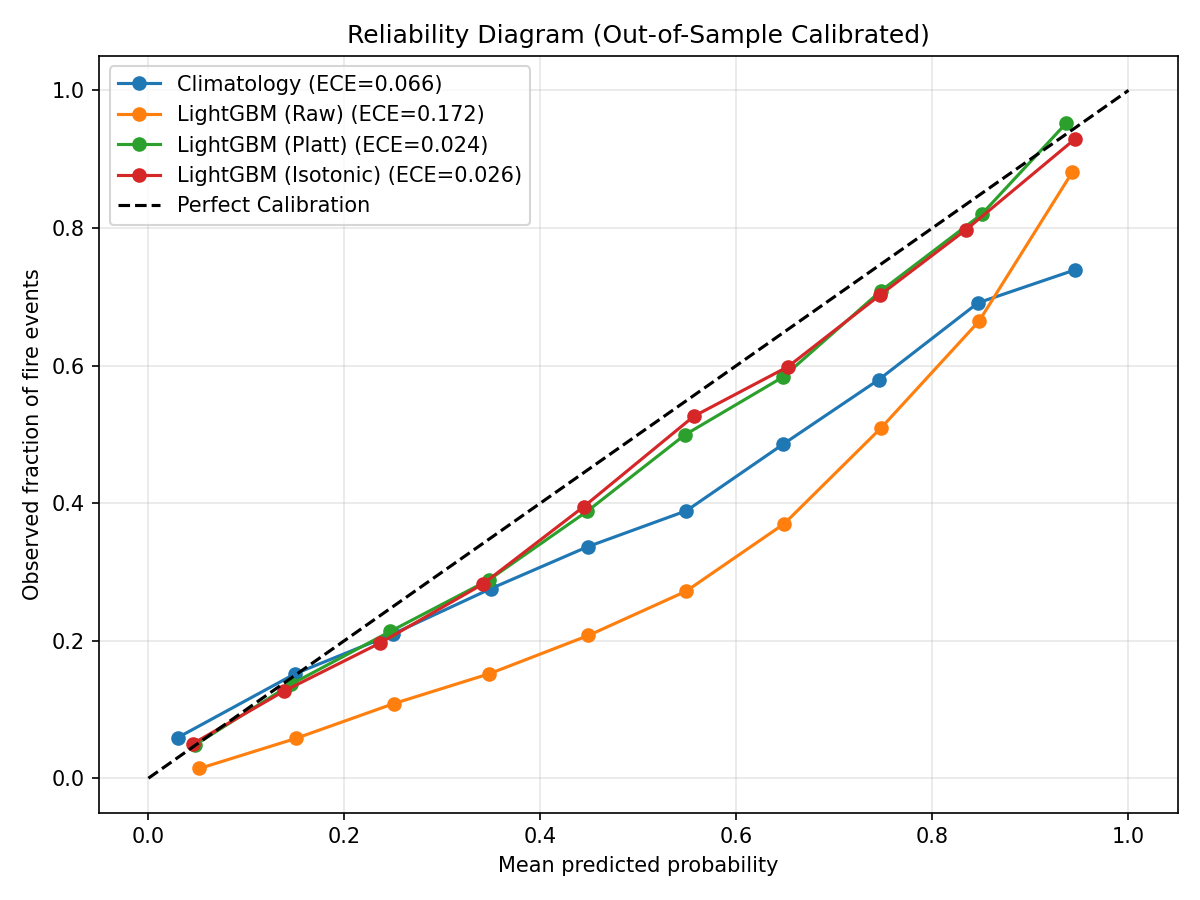

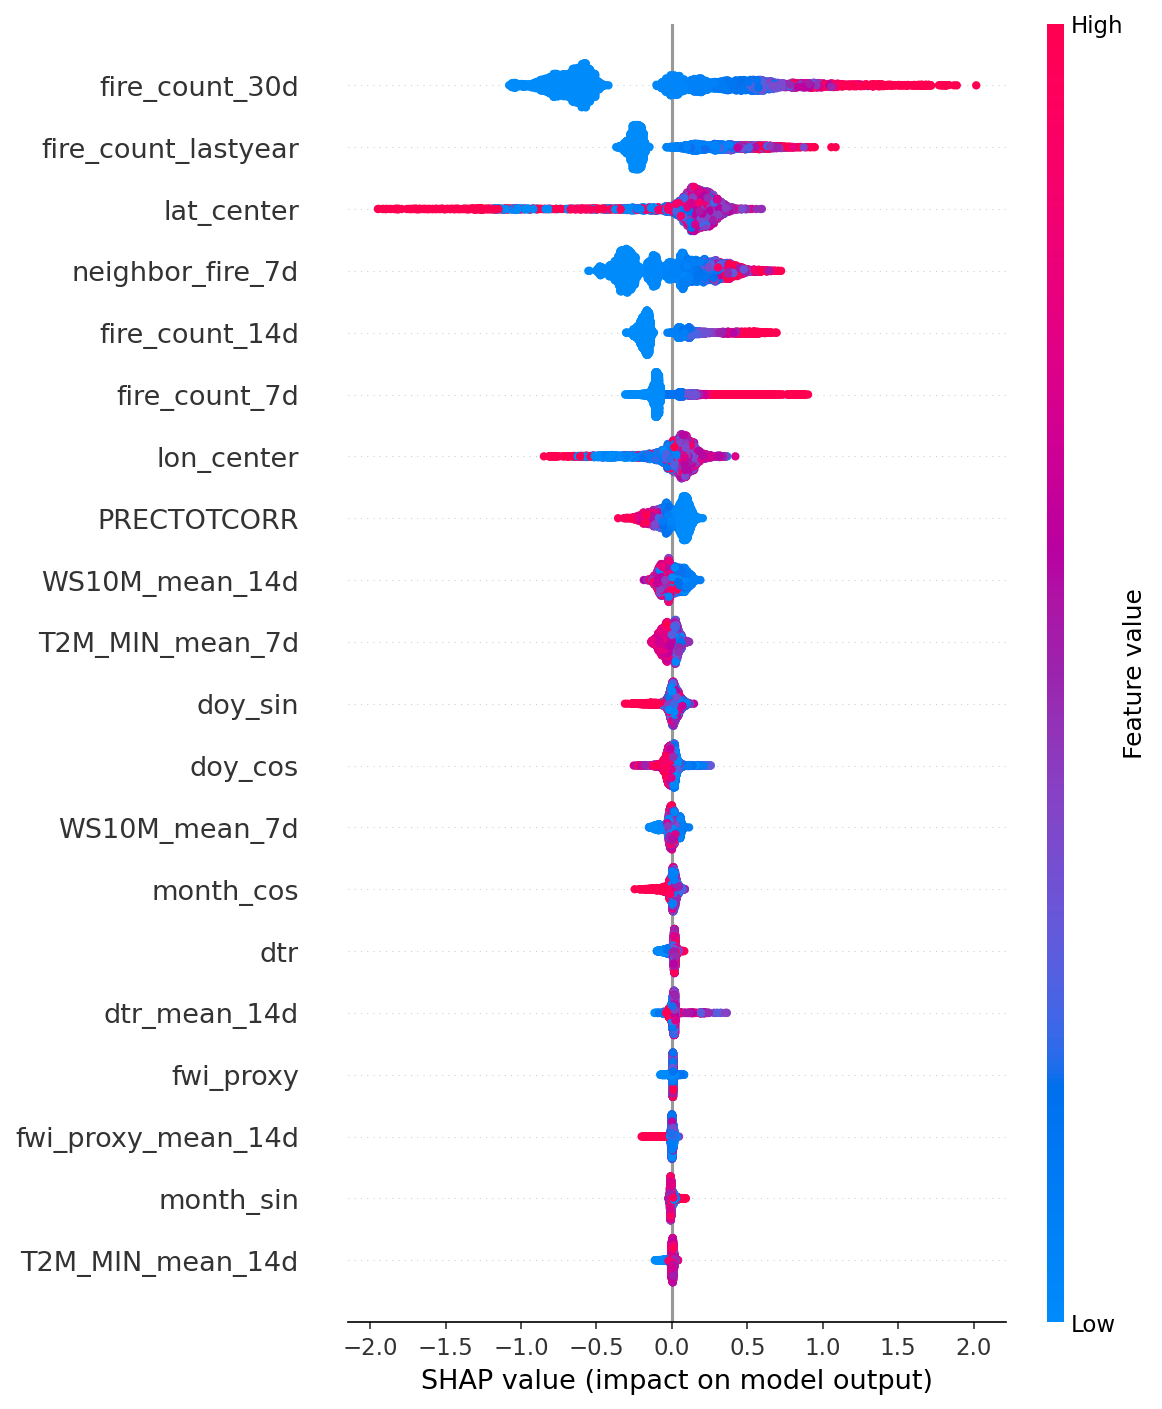

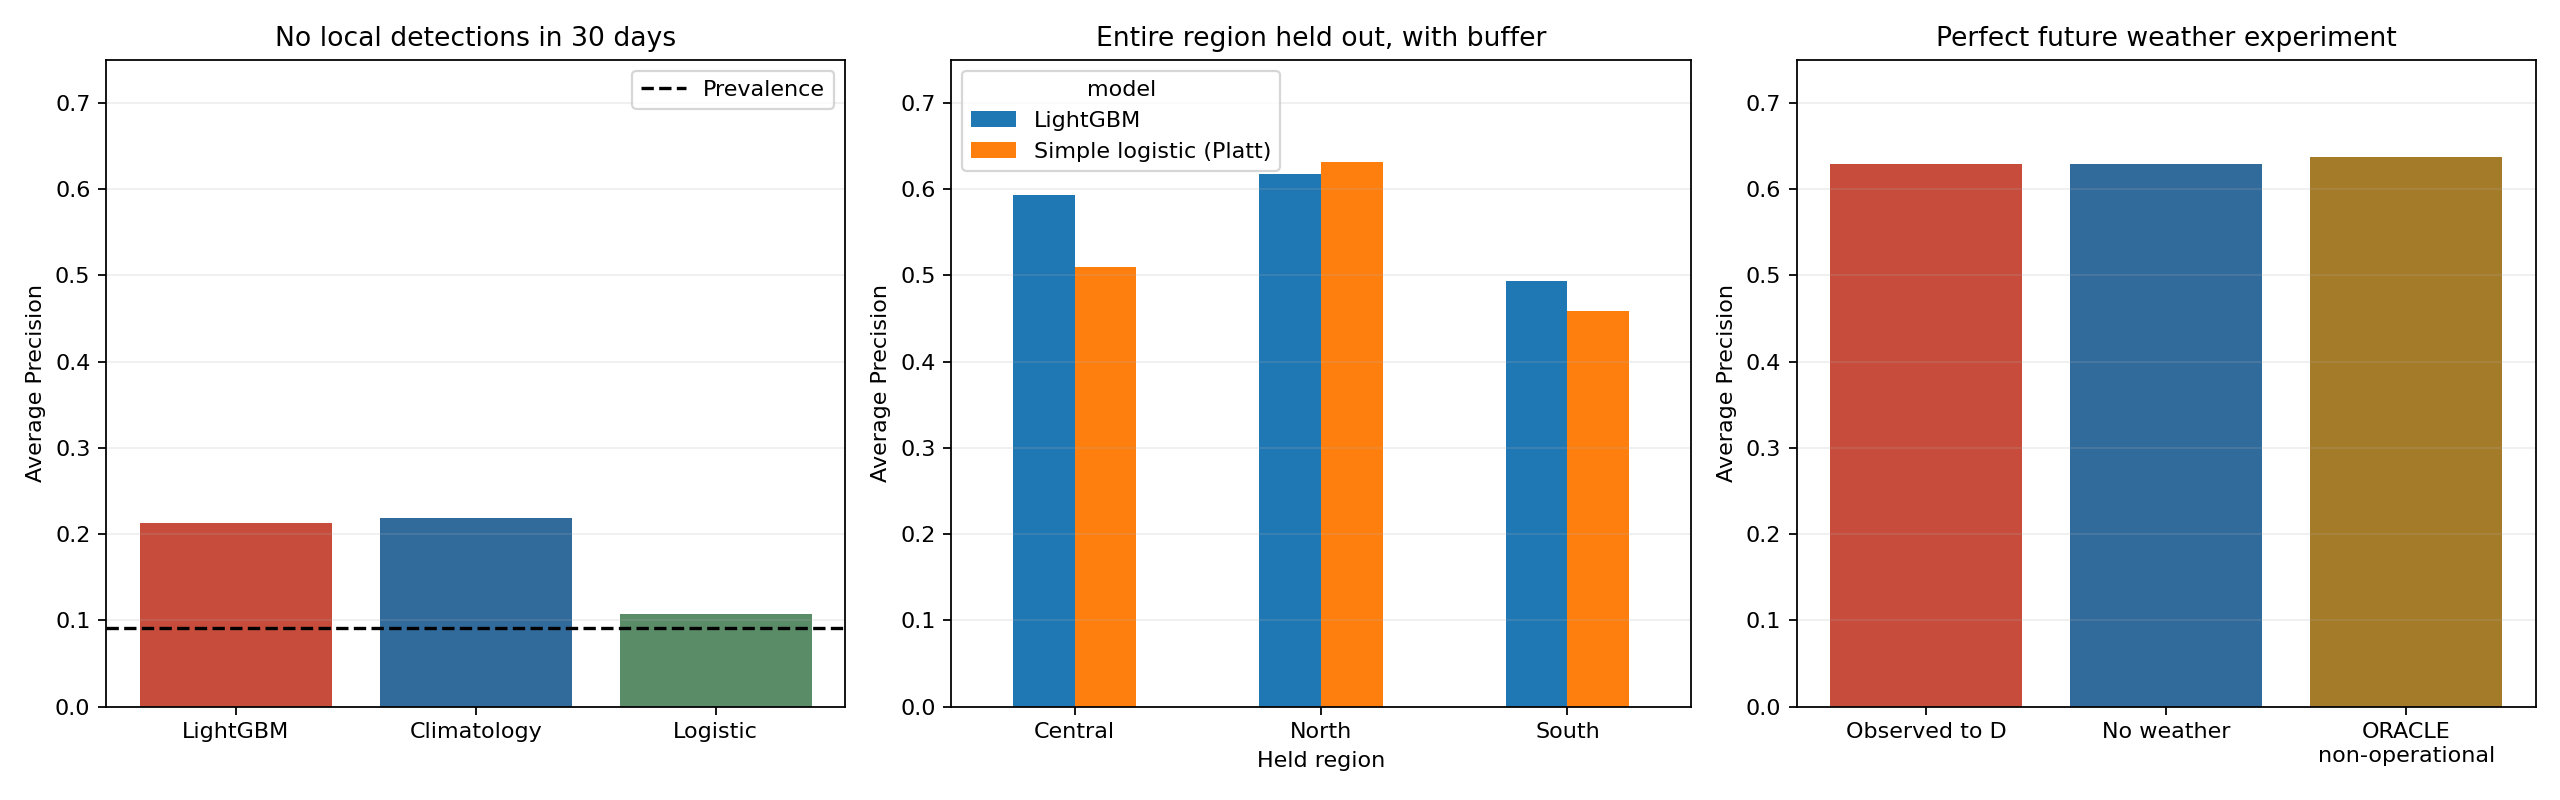

In [7]:
for filename in ['calibration_curve.png', 'shap_summary.png', 'research_summary.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / filename)))


SHAP descreve contribuições à margem bruta; não decompõe a probabilidade calibrada nem identifica causalidade. O calendário dos focos foi verificado; os horários históricos de publicação e os metadados climáticos originais não foram recuperados integralmente. Esta análise retrospectiva não valida operação real.